In [19]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [21]:
df = pd.read_csv("wine_quality_merged.csv")


In [23]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [25]:
# 2. Separate features and class labels
X = df.drop(["type", "quality"], axis=1)
y = df["type"]

In [27]:
X = StandardScaler().fit_transform(X)

In [29]:
# Apply PCA to reduce dimensions to 2
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

In [31]:
print("Explained variance:", pca.explained_variance_ratio_.sum()*100,"%")

Explained variance: 0.502154061434358


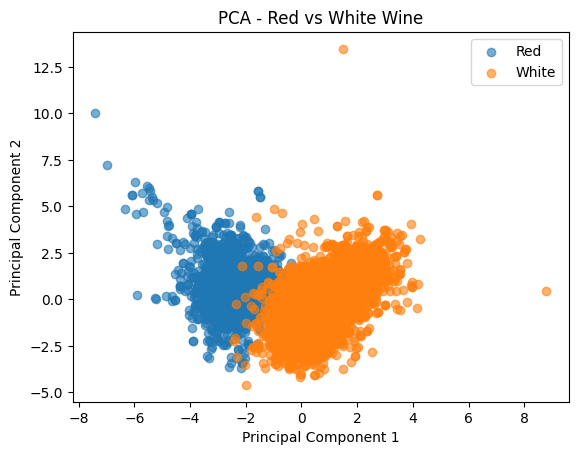

In [33]:
# 5. Visualize red and white wine
for c in ["red", "white"]:
    plt.scatter(
        X_pca[y.to_numpy() == c, 0],
        X_pca[y.to_numpy() == c, 1],
        label=c.capitalize(),
        alpha=0.6
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA - Red vs White Wine")
plt.legend()
plt.show()

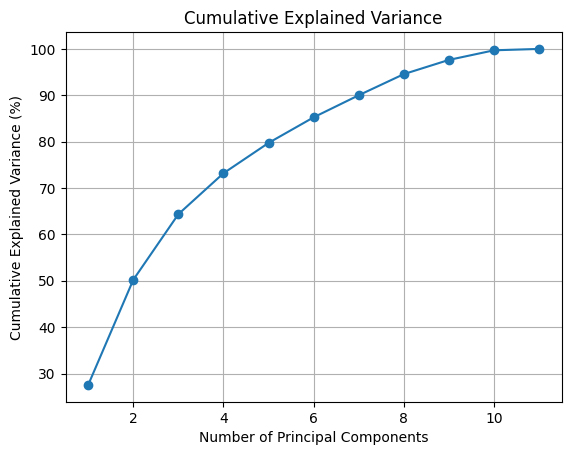

In [35]:
# Cumulative Explained Variance
pca_full = PCA()
pca_full.fit(X)

plt.plot(range(1, X.shape[1] + 1),
         pca_full.explained_variance_ratio_.cumsum() * 100,
         marker="o")

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("Cumulative Explained Variance")
plt.grid()
plt.show()